In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [ ]:
# Operators

def grad2(F, dx, dy):
    return (
        np.gradient(F, dx, axis=0, edge_order=2),
        np.gradient(F, dy, axis=1, edge_order=2),
    )

def lap2(F, dx, dy):
    Fx, Fy = grad2(F, dx, dy)
    return np.gradient(Fx, dx, axis=0, edge_order=2) + np.gradient(Fy, dy, axis=1, edge_order=2)

def A_of_F(rho, F, dx, dy):
    rx, ry = grad2(rho, dx, dy)
    Fx, Fy = grad2(F, dx, dy)
    return rx * Fx + ry * Fy + rho * lap2(F, dx, dy)


# Basis dictionaries for V(x1,x2)

def build_poly_basis_2d(X1, X2, degree=4, L=5.0):
    x, y = X1 / L, X2 / L
    Phi, params = [], []
    for i in range(degree + 1):
        for j in range(degree + 1 - i):
            if i + j == 0:
                continue
            Phi.append(x**i * y**j)
            params.append((i, j))
    return {"name": "polynomial", "Phi": np.asarray(Phi), "params": params}

def build_fourier_basis_2d(X1, X2, L=6.0, modes=4):
    Phi, params = [], []
    for k in range(1, modes + 1):
        for l in range(1, modes + 1):
            Phi.append(np.sin(k * np.pi * X1 / L) * np.cos(l * np.pi * X2 / L))
            params.append(("sin-cos", k, l))
            Phi.append(np.cos(k * np.pi * X1 / L) * np.sin(l * np.pi * X2 / L))
            params.append(("cos-sin", k, l))
    return {"name": "fourier", "Phi": np.asarray(Phi), "params": params}

def build_gaussian_basis_2d(X1, X2, centers, sigma=1.0):
    Phi, params = [], []
    for c1, c2 in centers:
        r2 = (X1 - c1)**2 + (X2 - c2)**2
        Phi.append(np.exp(-0.5 * r2 / sigma**2))
        params.append((c1, c2))
    return {"name": "gaussian", "Phi": np.asarray(Phi), "params": params}


# Sparse solver
def partinv(A, b, K=8, max_iter=100, tol=1e-12):
    n = A.shape[1]
    I = np.argsort(np.abs(A.T @ b))[-K:]
    hist = []
    for _ in range(max_iter):
        I = np.array(sorted(I))
        hist.append(tuple(I.tolist()))
        AI = A[:, I]
        cI = np.linalg.pinv(AI) @ b
        r = b - AI @ cI
        proxy = np.zeros(n)
        proxy[I] = cI
        J = np.setdiff1d(np.arange(n), I)
        proxy[J] = A[:, J].T @ r
        I_new = np.argsort(np.abs(proxy))[-K:]
        if set(I_new.tolist()) == set(I.tolist()) or np.linalg.norm(r) < tol:
            I = np.array(sorted(I_new))
            break
        I = I_new
    c = np.zeros(n)
    c[I] = np.linalg.pinv(A[:, I]) @ b
    return c, I, list(dict.fromkeys(hist))

def restricted_ls(A, b, support):
    support = np.array(sorted(support))
    c = np.zeros(A.shape[1])
    c[support] = np.linalg.pinv(A[:, support]) @ b
    return c, np.linalg.norm(A @ c - b)

def re_pruning(A, b, candidate_support, sparsity, max_cand=14):
    candidate_support = sorted(set(candidate_support))
    if len(candidate_support) > max_cand:
        proxy = np.abs(A[:, candidate_support].T @ b)
        keep = np.argsort(proxy)[-max_cand:]
        candidate_support = [candidate_support[i] for i in keep]
    records = []
    for J in combinations(candidate_support, sparsity):
        c, res = restricted_ls(A, b, J)
        records.append((res, J, c))
    return sorted(records, key=lambda z: z[0])


# Data and design matrix
def prepare_whf_sparse_data(data_file, rho_cutoff):
    D = np.load(data_file)
    rho = D["rho"].astype(np.float64)
    phi = D["phi"].astype(np.float64)
    H_god = D["H_god"].astype(np.float64)
    Uprime = D["Uprime"].astype(np.float64)
    V_true = D["V_true"].astype(np.float64)
    x1, x2 = D["x1_obs"], D["x2_obs"]
    dx, dy, dt = float(D["dx"]), float(D["dy"]), float(D["dt"])
    Nt, Nx, Ny = rho.shape
    time_ids = np.arange(1, Nt - 1)
    phi_t = np.zeros_like(phi)
    phi_t[1:-1] = (phi[2:] - phi[:-2]) / (2.0 * dt)
    f_delta = np.zeros_like(rho)
    for l in time_ids:
        f_delta[l] = -A_of_F(rho[l], phi_t[l] + H_god[l] + Uprime[l], dx, dy)
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    mask_t = np.zeros_like(rho, dtype=bool)
    mask_t[time_ids] = True
    mask = (rho > rho_cutoff) & mask_t
    return dict(
        rho=rho,
        f_delta=f_delta,
        V_true=V_true,
        x1=x1,
        x2=x2,
        X1=X1,
        X2=X2,
        dx=dx,
        dy=dy,
        time_ids=time_ids,
        mask=mask,
        rho_bar=np.mean(rho[time_ids], axis=0),
    )

def build_design(S, basis, M, alpha, seed):
    rng = np.random.default_rng(seed)
    rho = S["rho"]
    f_delta = S["f_delta"]
    mask = S["mask"]
    Phi = basis["Phi"]
    dx, dy = S["dx"], S["dy"]
    rho_x = np.zeros_like(rho)
    rho_y = np.zeros_like(rho)
    for l in S["time_ids"]:
        rho_x[l], rho_y[l] = grad2(rho[l], dx, dy)
    idx_all = np.flatnonzero(mask.reshape(-1))
    rho_all = rho.reshape(-1)[idx_all]
    M = min(M, len(idx_all))
    prob = alpha * rho_all / rho_all.sum() + (1.0 - alpha) / len(idx_all)
    prob /= prob.sum()
    idx = rng.choice(idx_all, size=M, replace=False, p=prob)
    rows = np.unravel_index(idx, rho.shape)
    B = np.zeros((M, len(Phi)))
    for j, P in enumerate(Phi):
        Px, Py = grad2(P, dx, dy)
        LP = lap2(P, dx, dy)
        B[:, j] = (
            rho_x[rows] * Px[rows[1], rows[2]]
            + rho_y[rows] * Py[rows[1], rows[2]]
            + rho[rows] * LP[rows[1], rows[2]]
        )
    w = np.sqrt(rho[rows])
    return B * w[:, None], f_delta[rows] * w

# Run sparse recovery
def rel_l2_box(F, G, X1, X2, R):
    mask = (np.abs(X1) <= R) & (np.abs(X2) <= R)
    return np.linalg.norm(F[mask] - G[mask]) / np.linalg.norm(G[mask])

def run_sparse_V(data_file, basis, params):
    os.makedirs(params["outdir"], exist_ok=True)
    S = prepare_whf_sparse_data(data_file, rho_cutoff=params["rho_cutoff"])
    A, b = build_design(S, basis, M=params["M"], alpha=params["alpha"], seed=params["seed"])
    col_norm = np.linalg.norm(A, axis=0) + 1e-14
    A0 = A / col_norm
    _, supp, hist = partinv(A0, b, K=params["K_partinv"])
    candidate_support = sorted(set(np.concatenate([np.array(h) for h in hist]))) if hist else supp.tolist()
    if len(candidate_support) < params["sparsity"]:
        candidate_support = supp.tolist()
    res, support, c0 = re_pruning(A0, b, candidate_support, sparsity=params["sparsity"], max_cand=params["max_cand"])[0]
    c = c0 / col_norm
    V_hat = np.tensordot(c, basis["Phi"], axes=(0, 0))
    V_hat += (
        np.sum(S["rho_bar"] * (S["V_true"] - V_hat))
        / np.sum(S["rho_bar"])
    )
    err2 = rel_l2_box(V_hat, S["V_true"], S["X1"], S["X2"], 2)
    err4 = rel_l2_box(V_hat, S["V_true"], S["X1"], S["X2"], 4)
    print("basis =", basis["name"])
    print("support =", support)
    print("residual =", res)
    print("[-2,2]^2 error =", err2)
    print("[-4,4]^2 error =", err4)
    prefix = f"{params['outdir']}/{params['tag']}_{basis['name']}"
    return dict(
        S=S,
        basis=basis,
        coef=c,
        support=support,
        V_hat=V_hat,
        V_true=S["V_true"],
        x1=S["x1"],
        x2=S["x2"],
        err_abs=np.abs(V_hat - S["V_true"]),
        err2=err2,
        err4=err4,
        residual=res,
    )

# Plots
def crop_box(x1, x2, F, R):
    ix = np.abs(x1) <= R
    iy = np.abs(x2) <= R
    return F[np.ix_(ix, iy)]

def plot_abs_error(R, save_name, Rbox=4):
    S = R["S"]
    err = np.abs(R["V_hat"] - S["V_true"])
    err_box = crop_box(S["x1"], S["x2"], err, Rbox)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(
        err_box.T,
        origin="lower",
        extent=[-Rbox, Rbox, -Rbox, Rbox],
        cmap="viridis",
        aspect="auto",
        interpolation="nearest",
    )
    fig.colorbar(im, ax=ax, label=r"$|V-\widehat V|$")
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_xlim(-Rbox, Rbox)
    ax.set_ylim(-Rbox, Rbox)
    fig.savefig(save_name, dpi=300, bbox_inches="tight", pad_inches=0.02)
    plt.show()

def plot_sparse_errors(results, outdir, Rbox=4):
    os.makedirs(outdir, exist_ok=True)
    for R in results:
        basis = R["basis"]["name"]
        plot_abs_error(R, f"{outdir}/{basis}_abs_error.png", Rbox=Rbox)

basis = polynomial
support = (1, 3, 10, 17)
residual = 5.494932727231976e-06
[-2,2]^2 error = 2.446024216080093e-05
[-4,4]^2 error = 1.429447795429332e-05
basis = fourier
support = (11, 13, 15, 27)
residual = 0.4710853320950393
[-2,2]^2 error = 1.3046684519649925
[-4,4]^2 error = 0.6364077822915216
basis = gaussian
support = (2, 11, 12, 22)
residual = 0.28757874194019095
[-2,2]^2 error = 0.8540461203855967
[-4,4]^2 error = 0.5880285563778341


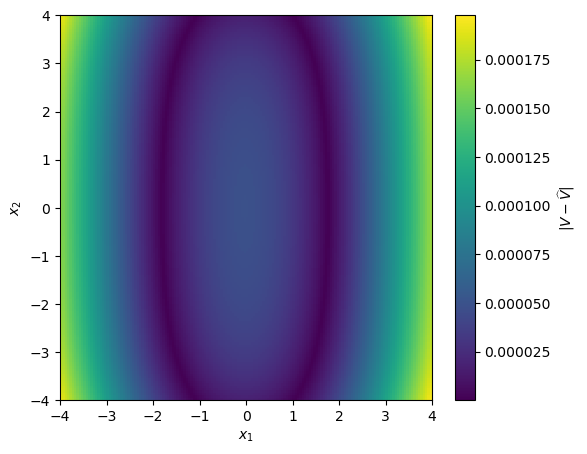

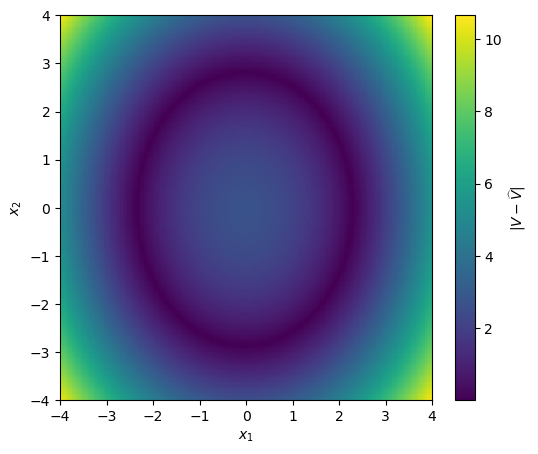

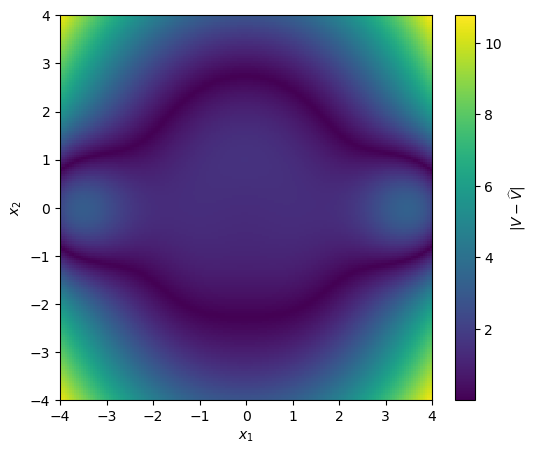

In [3]:
# example 3: polynomial
data_file = "data/example3_whf_polynomial_Cx5_Ct50.npz"
outdir = "figures_polynomial"
os.makedirs(outdir, exist_ok=True)
D = np.load(data_file)
x1, x2 = D["x1_obs"], D["x2_obs"]
X1, X2 = np.meshgrid(x1, x2, indexing="ij")
centers_1d = np.linspace(-4, 4, 5)
centers = [(a, b) for a in centers_1d for b in centers_1d]
bases = [
    build_poly_basis_2d(X1, X2, degree=5, L=5.0),
    build_fourier_basis_2d(X1, X2, L=6.0, modes=4),
    build_gaussian_basis_2d(X1, X2, centers=centers, sigma=1.0),
]
params = dict(
    M=8000,
    alpha=0.5,
    rho_cutoff=1e-5,
    K_partinv=8,
    sparsity=4,
    max_cand=14,
    seed=123,
    outdir=outdir,
    tag="example3",
)

R_poly = run_sparse_V(data_file, bases[0], params)
R_fourier = run_sparse_V(data_file, bases[1], params)
R_gaussian = run_sparse_V(data_file, bases[2], params)

plot_sparse_errors(
    [R_poly, R_fourier, R_gaussian],
    outdir=outdir,
    Rbox=4,
)

basis = polynomial
support = (5, 9, 14, 16)
residual = 1.5027601608508343
[-2,2]^2 error = 4.9971594194646665
[-4,4]^2 error = 67.241784610407
basis = fourier
support = (12, 20, 26, 30)
residual = 0.1508555394336759
[-2,2]^2 error = 0.409462359176446
[-4,4]^2 error = 0.6827244605592566
basis = gaussian
support = (6, 8, 16, 18)
residual = 1.5313126069702037
[-2,2]^2 error = 1.6895650206881347
[-4,4]^2 error = 2.3943641087873075


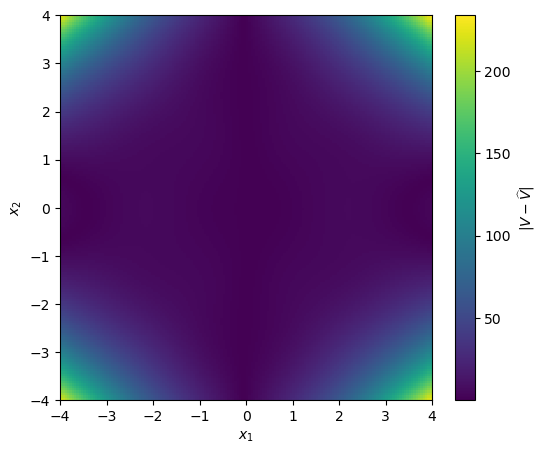

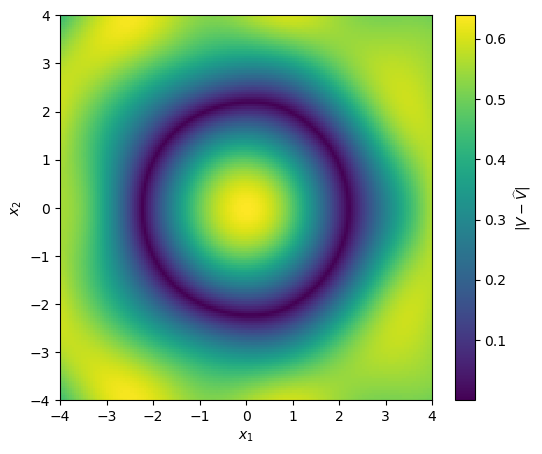

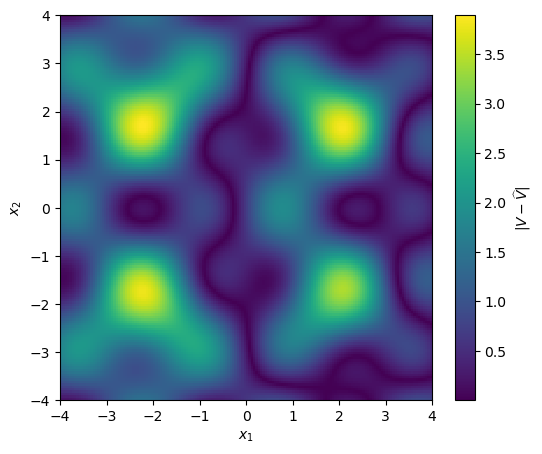

In [4]:
# example 4: highly_nonconvex potential
data_file = "data/example4_whf_highly_nonconvex_Cx5_Ct50.npz"
outdir = "figures_highly_nonconvex"
os.makedirs(outdir, exist_ok=True)
D = np.load(data_file)
x1, x2 = D["x1_obs"], D["x2_obs"]
X1, X2 = np.meshgrid(x1, x2, indexing="ij")
centers_1d = np.linspace(-4, 4, 5)
centers = [(a, b) for a in centers_1d for b in centers_1d]
bases = [
    build_poly_basis_2d(X1, X2, degree=5, L=5.0),
    build_fourier_basis_2d(X1, X2, L=6.0, modes=4),
    build_gaussian_basis_2d(X1, X2, centers=centers, sigma=1.0),
]

params = dict(
    M=8000,
    alpha=0.5,
    rho_cutoff=1e-5,
    K_partinv=8,
    sparsity=4,
    max_cand=14,
    seed=123,
    outdir=outdir,
    tag="example4",
)

R_poly = run_sparse_V(data_file, bases[0], params)
R_fourier = run_sparse_V(data_file, bases[1], params)
R_gaussian = run_sparse_V(data_file, bases[2], params)

plot_sparse_errors(
    [R_poly, R_fourier, R_gaussian],
    outdir=outdir,
    Rbox=4,
)